<a href="https://colab.research.google.com/github/maudem-data/DATA-101/blob/main/netflix_milestone3_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎬 Movie or TV Show? A Netflix Detective Story
### DATA 101 · Project Milestone 3: Statistical Tests & Predictive Modeling

---

**The challenge question:** *Can we tell whether a Netflix title is a **Movie** or a **TV Show** using only the other information about it?*

This is a **binary classification** problem: every title gets one of two labels. Along the way we'll also run two **statistical tests** to check whether patterns we see are real or just noise.

### 🎯 What this notebook demonstrates (Milestone 3 checklist)

| Milestone task | Where |
|---|---|
| Perform statistical tests | **Part 2**: t-test, bootstrap confidence interval, chi-square test |
| Choose a simple predictive model | **Part 3**: Logistic Regression (plus Random Forest for comparison) |
| Prepare data | **Part 3.1–3.3**: feature engineering, the data-leakage trap, train/test split |
| Train and evaluate | **Part 3.4–3.9**: baseline, metrics, confusion matrix, ROC curve, cross-validation |
| Evaluate uncertainty | **Parts 2 & 3.8**: confidence intervals, p-values, cross-validation spread |
| Ethics & limitations | **Part 4**: what the model can and **cannot** say |

### 🧭 How to use this notebook
- Run the cells **top to bottom** (`Shift + Enter`).
- 🧠 **Think** boxes ask you to predict *before* you see the answer. Write your guess down! Being wrong is how you learn.
- ✏️ **Your turn** boxes are small changes you can try.

## 🧠 Think first: Make your predictions

Before touching any code, jot down your guesses:

1. What percent of Netflix titles are movies? ______
2. Are TV shows on Netflix **newer** or **older** than movies, on average? ______
3. Which clue would help most to tell a movie from a TV show? ______
4. What accuracy do you think a model could reach? ______

We'll check every one of these against the data.

---
## Part 0: Setup

We import our tools. Think of these as the apps on your phone: each does one job.

| Library | Job |
|---|---|
| `pandas` | tables of data (like a spreadsheet) |
| `numpy` | fast math |
| `matplotlib` / `seaborn` | charts |
| `scipy.stats` | statistical tests |
| `sklearn` (scikit-learn) | machine learning models |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

# One "seed" so everyone in class gets the same random results
RANDOM_STATE = 42

# A consistent color story: blue = Movie, orange = TV Show (used in every chart)
MOVIE_COLOR, TV_COLOR, GRAY = '#2a78d6', '#eb6834', '#898781'
TYPE_COLORS = {'Movie': MOVIE_COLOR, 'TV Show': TV_COLOR}
# Colors for comparing models
MODEL_COLORS = {'Baseline': GRAY, 'Logistic Regression': '#6250d6', 'Random Forest': '#1baf7a'}

plt.rcParams.update({
    'figure.figsize': (10, 5), 'figure.dpi': 100,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.8,
    'axes.titleweight': 'bold', 'axes.titlesize': 13, 'axes.titlelocation': 'left',
})
print("✅ Libraries loaded!")

✅ Libraries loaded!


### Load the data
We load the Netflix dataset straight from GitHub. If you're offline, download the CSV and put it in the same folder as this notebook.

In [2]:
URL = 'https://raw.githubusercontent.com/maudem-data/DATA-101/main/datasets/netflix_titles.csv'

try:
    df = pd.read_csv(URL)
    print("✅ Loaded from GitHub")
except Exception:
    df = pd.read_csv('netflix_titles.csv')   # local fallback
    print("✅ Loaded from local file")

print(f"The dataset has {df.shape[0]:,} rows (titles) and {df.shape[1]} columns.")
df.head(3)

✅ Loaded from GitHub
The dataset has 8,807 rows (titles) and 12 columns.


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...


In [3]:
# A small helper: a value counts as "missing" if it's blank OR a placeholder like "Unknown Director"
def is_missing(column):
    text = column.astype('string').str.strip().str.lower()
    return (text.isna() | text.eq('') | text.str.startswith('unknown') | text.eq('not given')).fillna(True)

# Group rare ratings together so every group has enough titles to study
RATING_GROUPS = ['TV-MA', 'TV-14', 'TV-PG', 'R', 'PG-13', 'TV-Y7', 'TV-Y', 'PG', 'TV-G']
def group_rating(column):
    r = column.fillna('Other').astype(str).str.strip()
    return r.where(r.isin(RATING_GROUPS), 'Other')

df['release_year'] = pd.to_numeric(df['release_year'], errors='coerce')
df['rating_group'] = group_rating(df['rating'])
print("✅ Helper functions ready")

✅ Helper functions ready


---
## Part 1: Get to Know the Data (Exploratory Analysis)

Good detectives look at the scene before naming a suspect. Let's look at three things:
1. How many movies vs TV shows?
2. When were they released?
3. What ratings do they have?

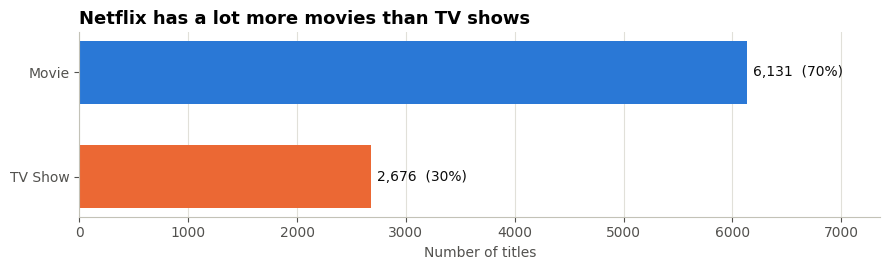

In [4]:
counts = df['type'].value_counts()
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(9, 2.8))
bars = ax.barh(counts.index, counts.values, color=[TYPE_COLORS[t] for t in counts.index], height=0.6)
for bar, c, p in zip(bars, counts.values, pct.values):
    ax.text(bar.get_width() + 60, bar.get_y() + bar.get_height()/2, f"{c:,}  ({p:.0f}%)",
            va='center', color='#0b0b0b')
ax.set_title("Netflix has a lot more movies than TV shows")
ax.set_xlabel("Number of titles")
ax.invert_yaxis(); ax.grid(axis='y', visible=False)
ax.set_xlim(0, counts.max() * 1.2)
plt.tight_layout(); plt.show()

> 💡 **Remember this number!** About **70% of titles are movies**. That means a "lazy" model that *always* guesses "Movie" would already be right about 70% of the time. Any real model has to **beat that**. We'll call it the **baseline**.

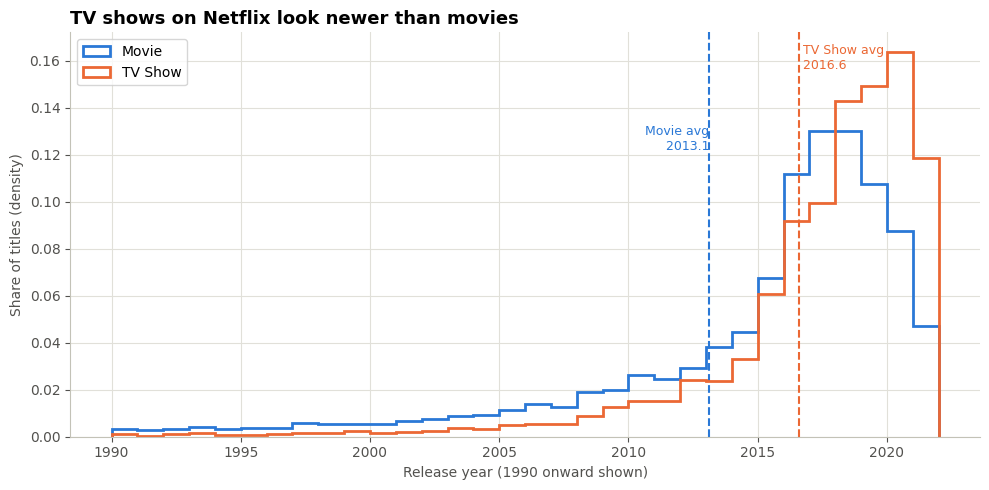

In [5]:
fig, ax = plt.subplots()
bins = np.arange(1990, 2023, 1)
for t in ['Movie', 'TV Show']:
    years = df.loc[df['type'] == t, 'release_year']
    ax.hist(years, bins=bins, density=True, histtype='step', linewidth=2, color=TYPE_COLORS[t], label=t)
    ax.axvline(years.mean(), color=TYPE_COLORS[t], linestyle='--', linewidth=1.5)
    ax.text(years.mean(), ax.get_ylim()[1] * 0.97, f" {t} avg\n {years.mean():.1f}", color=TYPE_COLORS[t],
            va='top', ha='right' if t == 'Movie' else 'left', fontsize=9)
ax.set_title("TV shows on Netflix look newer than movies")
ax.set_xlabel("Release year (1990 onward shown)")
ax.set_ylabel("Share of titles (density)")
ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

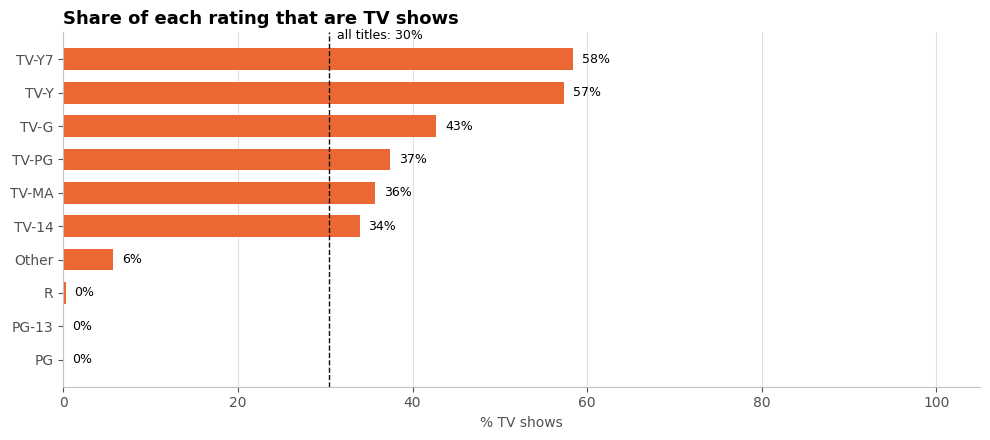

In [6]:
tv_share = (df.groupby('rating_group')['type']
              .apply(lambda s: (s == 'TV Show').mean() * 100)
              .sort_values())
overall = (df['type'] == 'TV Show').mean() * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(tv_share.index, tv_share.values, color=TV_COLOR, height=0.65)
for i, v in enumerate(tv_share.values):
    ax.text(v + 1, i, f"{v:.0f}%", va='center', fontsize=9)
ax.axvline(overall, color='#0b0b0b', linestyle='--', linewidth=1)
ax.text(overall + 1, len(tv_share) - 0.4, f"all titles: {overall:.0f}%", fontsize=9)
ax.set_title("Share of each rating that are TV shows")
ax.set_xlabel("% TV shows"); ax.set_xlim(0, 105)
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

> 🧠 **Think:** Ratings like **R**, **PG-13** and **PG** are movie-theater ratings, so they're almost never TV shows. Ratings starting with **TV-** can be either. Does that match what you expected?

We *see* differences in these charts. But are they **real**, or could they be random luck? That's what statistical tests are for. 👇

---
## Part 2: Statistical Tests: Is the Pattern Real?

### How every hypothesis test works (in plain English)
1. **Null hypothesis (H₀):** the boring explanation: "there's no real difference."
2. **Alternative hypothesis (H₁):** "there *is* a real difference."
3. Compute a **p-value**: *if the boring explanation were true, how surprising would our data be?*
4. If p < 0.05 (our **significance level**, α), we say the result is **statistically significant** and reject H₀.

> ⚠️ A p-value is **not** "the chance H₀ is true." It's the chance of seeing data this extreme *if* H₀ were true.

---
### Test 1: Are TV shows released more recently than movies? (Welch's t-test)

- **H₀:** Movies and TV shows have the same average release year.
- **H₁:** Their average release years are different.

We use **Welch's t-test**, which compares two group averages and does *not* assume both groups have the same spread.

In [7]:
movie_years = df.loc[df['type'] == 'Movie', 'release_year'].dropna()
tv_years    = df.loc[df['type'] == 'TV Show', 'release_year'].dropna()

t_stat, p_value = stats.ttest_ind(tv_years, movie_years, equal_var=False)   # Welch's t-test
diff = tv_years.mean() - movie_years.mean()

# Effect size (Cohen's d): how big is the difference compared to the normal spread?
pooled_sd = np.sqrt((movie_years.var() + tv_years.var()) / 2)
cohens_d = diff / pooled_sd

print(f"Average release year: Movies = {movie_years.mean():.1f}, TV Shows = {tv_years.mean():.1f}")
print(f"Difference: TV shows are {diff:.1f} years newer on average")
print(f"t-statistic = {t_stat:.2f}")
print(f"p-value     = {p_value:.2e}")
print(f"Cohen's d   = {cohens_d:.2f}  (rule of thumb: 0.2 small, 0.5 medium, 0.8 large)")
print()
print("✅ Reject H₀: the difference is statistically significant." if p_value < 0.05
      else "❌ Fail to reject H₀: no significant difference.")

Average release year: Movies = 2013.1, TV Shows = 2016.6
Difference: TV shows are 3.5 years newer on average
t-statistic = 20.98
p-value     = 3.71e-95
Cohen's d   = 0.44  (rule of thumb: 0.2 small, 0.5 medium, 0.8 large)

✅ Reject H₀: the difference is statistically significant.


#### How sure are we about the size of the difference? A bootstrap confidence interval

A p-value says *whether* there's a difference. A **confidence interval** says *how big* it probably is.

The **bootstrap** is a beautifully simple idea: pretend our data *is* the population, **resample it with replacement thousands of times**, and recompute the difference each time. The spread of those results shows our uncertainty.

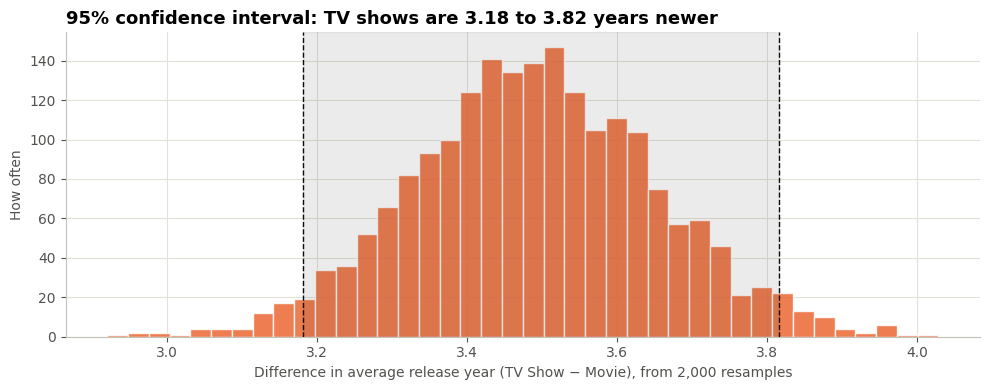

95% CI for the difference: [3.18, 3.82] years. Zero is not in the interval.


In [8]:
rng = np.random.default_rng(RANDOM_STATE)
mv, tv = movie_years.to_numpy(), tv_years.to_numpy()
n_boot = 2000

boot_diffs = np.array([
    rng.choice(tv, size=len(tv)).mean() - rng.choice(mv, size=len(mv)).mean()
    for _ in range(n_boot)
])
ci_low, ci_high = np.percentile(boot_diffs, [2.5, 97.5])

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(boot_diffs, bins=40, color=TV_COLOR, alpha=0.85, edgecolor='white')
ax.axvspan(ci_low, ci_high, color='#0b0b0b', alpha=0.08)
for x in (ci_low, ci_high):
    ax.axvline(x, color='#0b0b0b', linestyle='--', linewidth=1)
ax.set_title(f"95% confidence interval: TV shows are {ci_low:.2f} to {ci_high:.2f} years newer")
ax.set_xlabel("Difference in average release year (TV Show − Movie), from 2,000 resamples")
ax.set_ylabel("How often")
plt.tight_layout(); plt.show()
print(f"95% CI for the difference: [{ci_low:.2f}, {ci_high:.2f}] years. Zero is not in the interval.")

> 🧠 **Think:** Notice the interval doesn't include 0. That agrees with the tiny p-value.
>
> ⚠️ **Limitation:** With thousands of titles, even *tiny* differences become "significant." **Significant ≠ important.** That's why we also report the effect size (Cohen's d) and the confidence interval.
>
> ⚠️ **Limitation:** Release years are skewed (lots of recent titles, a long tail of old movies). The t-test is fairly robust with large samples, but a non-parametric check is a good habit. Let's run one.

In [ ]:
# Mann-Whitney U test: compares the groups using ranks, so it doesn't assume a bell curve
u_stat, p_mw = stats.mannwhitneyu(tv_years, movie_years, alternative='two-sided')
print(f"Mann-Whitney U p-value = {p_mw:.2e}  → {'same conclusion ✅' if p_mw < 0.05 else 'different conclusion ⚠️'}")

---
### Test 2: Is a title's rating related to its type? (Chi-square test of independence)

Release year is a number, so we compared **averages**. Rating is a **category**, so we compare **counts** in a table instead.

- **H₀:** Rating and type are independent (knowing the rating tells you nothing about the type).
- **H₁:** Rating and type are related.

The chi-square test compares the counts we **observed** with the counts we'd **expect** if there were no relationship.

In [9]:
table = pd.crosstab(df['rating_group'], df['type'])
chi2, p_chi, dof, expected = stats.chi2_contingency(table)

# Cramér's V = effect size for chi-square (0 = no relationship, 1 = perfect relationship)
cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

print("Observed counts:")
print(table)
print(f"\nchi-square = {chi2:.1f}, degrees of freedom = {dof}, p-value = {p_chi:.2e}")
print(f"Cramér's V = {cramers_v:.2f}  (rule of thumb: 0.1 small, 0.3 medium, 0.5 large)")
print(f"Smallest expected count = {expected.min():.1f}  (the test needs every expected count ≥ 5)")
print("\n✅ Reject H₀: rating and type are related." if p_chi < 0.05 else "\n❌ Fail to reject H₀.")

Observed counts:
type          Movie  TV Show
rating_group                
Other           132        8
PG              287        0
PG-13           490        0
R               797        2
TV-14          1427      733
TV-G            126       94
TV-MA          2062     1145
TV-PG           540      323
TV-Y            131      176
TV-Y7           139      195

chi-square = 1043.4, degrees of freedom = 9, p-value = 7.47e-219
Cramér's V = 0.34  (rule of thumb: 0.1 small, 0.3 medium, 0.5 large)
Smallest expected count = 42.5  (the test needs every expected count ≥ 5)

✅ Reject H₀: rating and type are related.


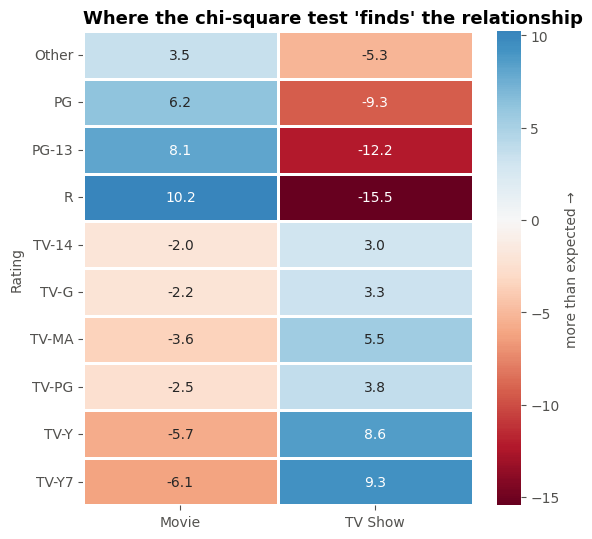

In [10]:
# Which cells are most surprising? Standardized residuals: (observed − expected) / √expected
residuals = (table - expected) / np.sqrt(expected)

fig, ax = plt.subplots(figsize=(6, 5.5))
sns.heatmap(residuals, annot=True, fmt='.1f', cmap='RdBu', center=0, cbar_kws={'label': 'more than expected →'},
            linewidths=2, linecolor='white', ax=ax)
ax.grid(False)
ax.set_title("Where the chi-square test 'finds' the relationship")
ax.set_xlabel(""); ax.set_ylabel("Rating")
plt.tight_layout(); plt.show()

> **How to read this:** Values far from 0 are surprising. A big **positive** number means *more titles than we'd expect if there were no relationship*. Here, **R** and **PG-13** have far more movies than expected, and **TV-Y / TV-Y7** (kids' shows) more TV shows.
>
> 📝 **Statistical tests summary:** Both tests say the differences are real, not random luck. TV shows are newer (with a modest effect size), and rating is strongly linked to type. That suggests **release year** and **rating** are useful clues for a predictive model.

---
## Part 3: Build a Predictive Model

### 3.1 Feature engineering: turning raw columns into clues

Models only understand **numbers**. So we turn each column into numeric "clues" (called **features**).

| Feature | How we made it | Why it might help |
|---|---|---|
| `release_year` | as is | TV shows looked newer (Test 1) |
| `year_added` | year from `date_added` | when Netflix acquired it |
| `years_until_added` | year_added − release_year | old classics are often movies |
| `director_missing` | 1 if no director is listed | TV shows list *creators*, not directors |
| `cast_missing`, `num_cast` | count names in `cast` | shows can have large ensemble casts |
| `country_missing`, `num_countries`, `is_us` | from `country` | co-productions & origin |
| `description_length`, `title_length` | number of characters | writing style differences? |
| `rating_*` | one 0/1 column per rating ("one-hot encoding") | strong link from Test 2 |

We put this in a **function** so we can reuse the exact same steps on brand-new titles later.

In [11]:
def build_features(data):
    # Turn raw Netflix rows into a table of numeric features
    f = pd.DataFrame(index=data.index)

    f['release_year'] = pd.to_numeric(data['release_year'], errors='coerce')
    added = pd.to_datetime(data['date_added'].astype('string').str.strip(), errors='coerce', format='mixed')
    f['year_added'] = added.dt.year
    f['years_until_added'] = (f['year_added'] - f['release_year']).clip(lower=0)

    f['director_missing'] = is_missing(data['director']).astype(int)
    f['cast_missing']     = is_missing(data['cast']).astype(int)
    f['country_missing']  = is_missing(data['country']).astype(int)

    cast    = data['cast'].fillna('').astype(str)
    country = data['country'].fillna('').astype(str)
    f['num_cast']      = (cast.str.count(',') + 1).where(f['cast_missing'] == 0, 0)
    f['num_countries'] = (country.str.count(',') + 1).where(f['country_missing'] == 0, 0)
    f['is_us']         = country.str.contains('United States').astype(int)

    f['description_length'] = data['description'].fillna('').astype(str).str.len()
    f['title_length']       = data['title'].fillna('').astype(str).str.len()

    # One-hot encode the rating: one 0/1 column per rating group (always the same columns)
    rating = group_rating(data['rating'])
    for r in RATING_GROUPS + ['Other']:
        f[f'rating_{r}'] = (rating == r).astype(int)
    return f

X_all = build_features(df)
y = (df['type'] == 'Movie').astype(int)        # target: 1 = Movie, 0 = TV Show

print(f"✅ Built {X_all.shape[1]} features for {X_all.shape[0]:,} titles")
X_all.head()

✅ Built 21 features for 8,807 titles


,release_year,year_added,years_until_added,director_missing,cast_missing,country_missing,num_cast,num_countries,is_us,description_length,...,rating_TV-MA,rating_TV-14,rating_TV-PG,rating_R,rating_PG-13,rating_TV-Y7,rating_TV-Y,rating_PG,rating_TV-G,rating_Other
0,2020,2021.0,1.0,0,1,0,0,1,1,152,...,0,0,0,0,1,0,0,0,0,0
1,2021,2021.0,0.0,1,0,0,19,1,0,147,...,1,0,0,0,0,0,0,0,0,0
2,2021,2021.0,0.0,0,0,1,9,0,0,146,...,1,0,0,0,0,0,0,0,0,0
3,2021,2021.0,0.0,1,1,1,0,0,0,147,...,1,0,0,0,0,0,0,0,0,0
4,2021,2021.0,0.0,1,0,0,8,1,0,152,...,1,0,0,0,0,0,0,0,0,0


### 3.2 🚨 The Data Leakage Trap: "Too Good to Be True"

The original version of this project used the `duration` column. It seems like a great clue... let's see what happens.

In [12]:
duration_number = pd.to_numeric(df['duration'].astype(str).str.split().str[0], errors='coerce')
duration_unit   = df['duration'].astype(str).str.split().str[1]

print("What units does 'duration' use?")
print(pd.crosstab(duration_unit, df['type']))

What units does 'duration' use?
type      Movie  TV Show
duration                
Season        0     1793
Seasons       0      883
min        6128        0


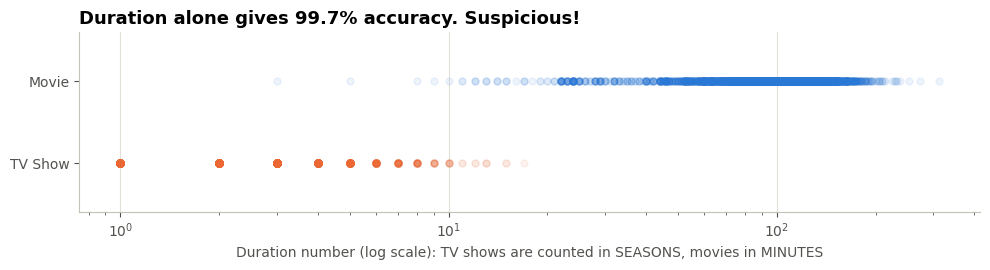

In [13]:
# A 1-feature model: predict type from duration alone
d = pd.DataFrame({'duration': duration_number}).fillna(duration_number.median())
d_tr, d_te, yd_tr, yd_te = train_test_split(d, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
leaky = LogisticRegression(max_iter=1000).fit(d_tr, yd_tr)
leaky_acc = accuracy_score(yd_te, leaky.predict(d_te))

fig, ax = plt.subplots(figsize=(10, 2.8))
for t in ['TV Show', 'Movie']:
    vals = duration_number[df['type'] == t]
    ax.scatter(vals, np.full(len(vals), t) , alpha=0.08, s=25, color=TYPE_COLORS[t])
ax.set_xscale('log'); ax.margins(y=0.6)
ax.set_xlabel("Duration number (log scale): TV shows are counted in SEASONS, movies in MINUTES")
ax.set_title(f"Duration alone gives {leaky_acc*100:.1f}% accuracy. Suspicious!")
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

### 🕵️ Why is that cheating?

Look at the units: TV shows are measured in **seasons** (1, 2, 3…), movies in **minutes** (90, 120…). The *unit itself* gives away the answer. The model isn't learning anything about content; it's reading the answer key.

This is called **data leakage**: a feature secretly contains the thing you're trying to predict. It makes a model look brilliant in class and useless in the real world.

The genre column (`listed_in`) has the same problem. Check it:

In [14]:
genres = df['listed_in'].fillna('').astype(str)
says_tv     = genres.str.contains('TV')
says_movies = genres.str.contains('Movie')
print(f"Titles whose genre mentions 'TV':     {(df.loc[says_tv, 'type'] == 'TV Show').mean()*100:.1f}% are TV shows")
print(f"Titles whose genre mentions 'Movie':  {(df.loc[says_movies, 'type'] == 'Movie').mean()*100:.1f}% are movies")

Titles whose genre mentions 'TV':     100.0% are TV shows
Titles whose genre mentions 'Movie':  100.0% are movies


> ✅ **Decision:** We **remove** `duration` and `listed_in` from our model. The honest question is harder and more interesting:
>
> ***Can we tell a movie from a TV show WITHOUT being handed the answer?***
>
> 🧠 **Think:** Is `director_missing` also a kind of leakage? It's not *the answer*, but it reflects how Netflix *records* TV shows (creators instead of directors). We'll keep it, but remember that the model is partly learning **data-entry habits**, not content. We'll come back to this in Part 4.

### 3.3 Split the data: training set vs test set

We hide 20% of the titles in a **test set** that the model never sees while learning. It's like a final exam with questions you haven't seen. That's the only fair way to measure how well the model works on *new* titles.

`stratify=y` keeps the 70/30 movie/TV mix the same in both sets.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(f"Training set: {len(X_train):,} titles ({y_train.mean()*100:.0f}% movies)")
print(f"Test set:     {len(X_test):,} titles ({y_test.mean()*100:.0f}% movies)")

Training set: 7,045 titles (70% movies)
Test set:     1,762 titles (70% movies)


### 3.4 Start with a baseline

Our "lazy" model always guesses the most common class (Movie). If our real model can't beat this, it's useless.

In [16]:
results = {}     # we'll store every model's scores here

def evaluate(name, model, X_te=X_test, y_te=y_test, show=True):
    # Score a trained model on the test set and explain the numbers in plain English
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    scores = {
        'Accuracy':  accuracy_score(y_te, pred),
        'Precision': precision_score(y_te, pred, zero_division=0),
        'Recall':    recall_score(y_te, pred),
        'F1':        f1_score(y_te, pred),
        'ROC-AUC':   roc_auc_score(y_te, proba),
    }
    results[name] = scores
    if show:
        print(f"📊 {name}")
        print(f"  Accuracy  {scores['Accuracy']:.3f} → correct on {scores['Accuracy']*100:.1f}% of test titles")
        print(f"  Precision {scores['Precision']:.3f} → when it says 'Movie', it's right {scores['Precision']*100:.1f}% of the time")
        print(f"  Recall    {scores['Recall']:.3f} → it finds {scores['Recall']*100:.1f}% of the real movies")
        print(f"  F1        {scores['F1']:.3f} → balance of precision & recall")
        print(f"  ROC-AUC   {scores['ROC-AUC']:.3f} → 0.5 = coin flip, 1.0 = perfect ranking")
    return scores

baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
evaluate('Baseline', baseline);

📊 Baseline
  Accuracy  0.696 → correct on 69.6% of test titles
  Precision 0.696 → when it says 'Movie', it's right 69.6% of the time
  Recall    1.000 → it finds 100.0% of the real movies
  F1        0.821 → balance of precision & recall
  ROC-AUC   0.500 → 0.5 = coin flip, 1.0 = perfect ranking


> 🧠 **Think:** The baseline has high accuracy **and** 100% recall, yet it's useless: it never identifies a single TV show. This is why **accuracy alone can fool you** when the classes are unbalanced.

### 3.5 Model 1: Logistic Regression

**Logistic regression** adds up the clues, each with a weight, and squeezes the total through an S-shaped curve to get a **probability** between 0 and 1:

$$P(\text{Movie}) = \frac{1}{1 + e^{-(b_0 + b_1x_1 + b_2x_2 + \dots)}}$$

If P(Movie) > 0.5 → predict **Movie**; otherwise → **TV Show**.

We build it as a **pipeline**, a chain of steps that always run in the same order:
1. `SimpleImputer`: fill missing values with the median *of the training set*.
2. `StandardScaler`: put features on the same scale so years (≈2000) don't overpower 0/1 columns.
3. `LogisticRegression`: the model.

> 💡 Why a pipeline? It guarantees the test set is filled and scaled using *only training information*. Using test data during preparation would be another sneaky form of leakage.

In [17]:
log_reg = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
)
log_reg.fit(X_train, y_train)
evaluate('Logistic Regression', log_reg);

📊 Logistic Regression
  Accuracy  0.952 → correct on 95.2% of test titles
  Precision 0.958 → when it says 'Movie', it's right 95.8% of the time
  Recall    0.975 → it finds 97.5% of the real movies
  F1        0.966 → balance of precision & recall
  ROC-AUC   0.964 → 0.5 = coin flip, 1.0 = perfect ranking


### 3.6 What did logistic regression learn?

Each feature gets a **coefficient** (weight). Because we scaled the features, we can compare them:
- **Positive** (blue) → pushes toward **Movie**
- **Negative** (orange) → pushes toward **TV Show**
- Bigger bar → stronger clue

We also show the **odds ratio** = e^coefficient: *"a one-standard-deviation increase in this feature multiplies the odds of being a movie by ___."*

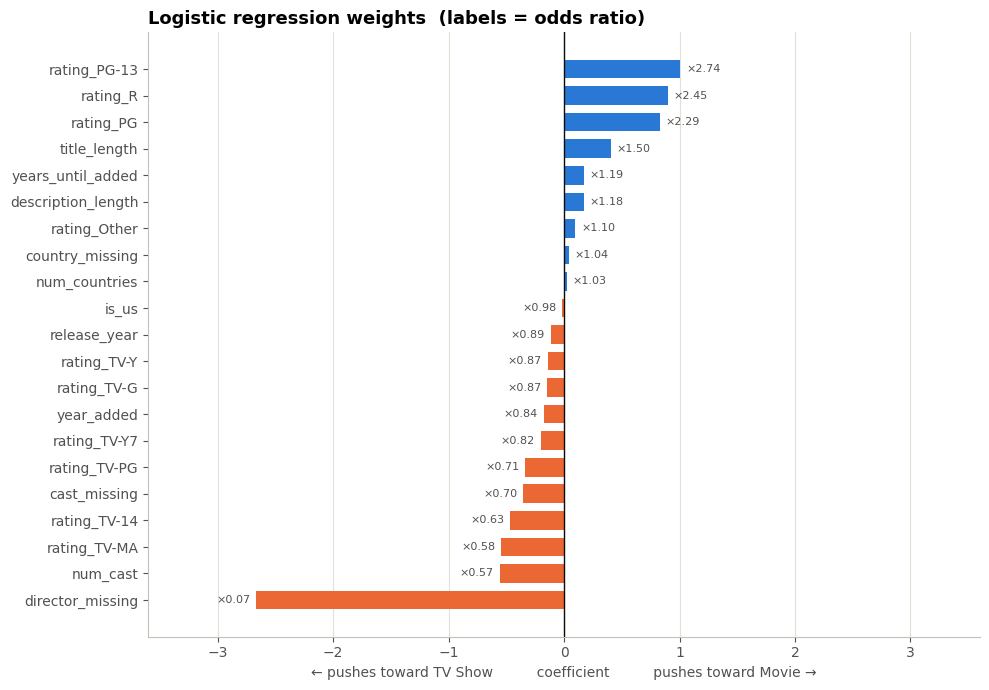

Strongest clues:
  • director_missing: coefficient -2.67 → TV Show
  • rating_PG-13: coefficient +1.01 → Movie
  • rating_R: coefficient +0.90 → Movie


In [18]:
coefs = pd.Series(log_reg[-1].coef_[0], index=X_train.columns).sort_values()
odds = np.exp(coefs)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(coefs.index, coefs.values, color=[MOVIE_COLOR if c > 0 else TV_COLOR for c in coefs], height=0.7)
ax.axvline(0, color='#0b0b0b', linewidth=1)
for i, (c, o) in enumerate(zip(coefs, odds)):
    ax.text(c + (0.05 if c >= 0 else -0.05), i, f"×{o:.2f}", va='center',
            ha='left' if c >= 0 else 'right', fontsize=8, color='#52514e')
ax.set_title("Logistic regression weights  (labels = odds ratio)")
ax.set_xlabel("← pushes toward TV Show          coefficient          pushes toward Movie →")
ax.grid(axis='y', visible=False)
xmax = np.abs(coefs).max() * 1.35
ax.set_xlim(-xmax, xmax)
plt.tight_layout(); plt.show()

print("Strongest clues:")
for feat in coefs.abs().sort_values(ascending=False).index[:3]:
    print(f"  • {feat}: coefficient {coefs[feat]:+.2f} → {'Movie' if coefs[feat] > 0 else 'TV Show'}")

> ⚠️ **Careful with interpretation:** These weights describe **associations in this dataset**, not causes. A missing director doesn't *make* something a TV show. It's just a pattern in how Netflix fills in its data.

### 3.7 Model 2: Random Forest (for comparison)

A **random forest** builds many **decision trees** (like a game of 20 Questions: *"Is a director listed? Is the rating TV-MA? Released after 2015?"*) and lets them **vote**.

- ✅ Can capture combinations of clues that logistic regression misses
- ❌ Harder to explain and more prone to **overfitting** (memorizing the training data)

We limit tree depth to reduce overfitting. Let's compare training vs test accuracy to check.

In [19]:
forest = make_pipeline(
    SimpleImputer(strategy='median'),
    RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=5,
                           random_state=RANDOM_STATE, n_jobs=-1)
)
forest.fit(X_train, y_train)
evaluate('Random Forest', forest)

for name, m in [('Logistic Regression', log_reg), ('Random Forest', forest)]:
    tr, te = accuracy_score(y_train, m.predict(X_train)), accuracy_score(y_test, m.predict(X_test))
    print(f"\n{name}: train accuracy {tr:.3f} vs test accuracy {te:.3f} → gap {tr-te:+.3f}"
          + ("  ⚠️ possible overfitting" if tr - te > 0.03 else "  ✅ small gap"))

📊 Random Forest
  Accuracy  0.953 → correct on 95.3% of test titles
  Precision 0.959 → when it says 'Movie', it's right 95.9% of the time
  Recall    0.974 → it finds 97.4% of the real movies
  F1        0.966 → balance of precision & recall
  ROC-AUC   0.979 → 0.5 = coin flip, 1.0 = perfect ranking

Logistic Regression: train accuracy 0.953 vs test accuracy 0.952 → gap +0.001  ✅ small gap

Random Forest: train accuracy 0.955 vs test accuracy 0.953 → gap +0.002  ✅ small gap


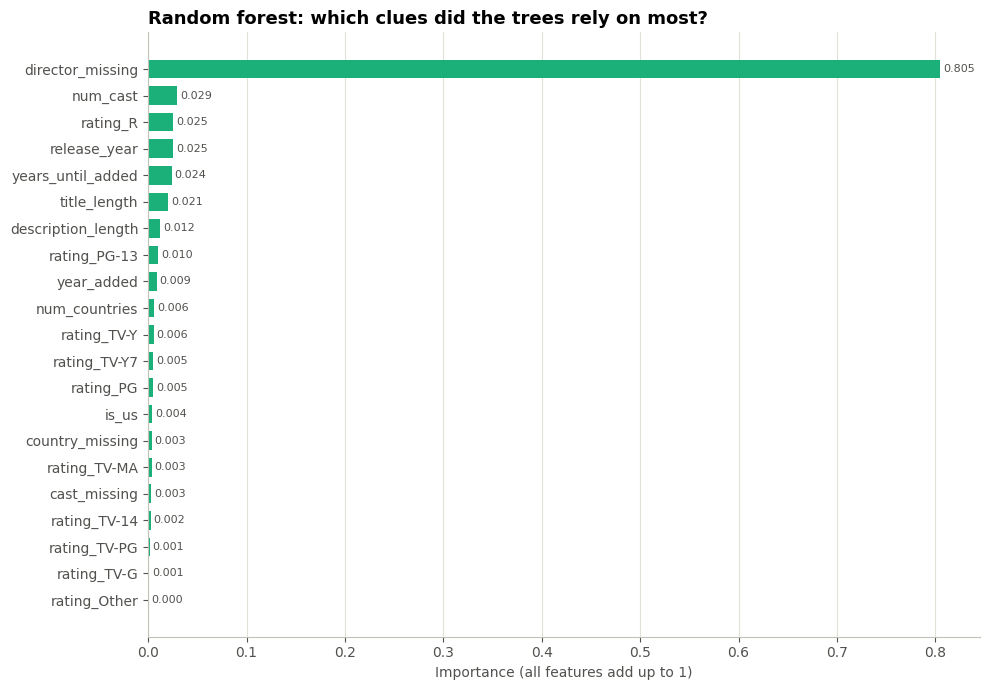

In [20]:
importances = pd.Series(forest[-1].feature_importances_, index=X_train.columns).sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(importances.index, importances.values, color=MODEL_COLORS['Random Forest'], height=0.7)
for i, v in enumerate(importances.values):
    ax.text(v + 0.003, i, f"{v:.3f}", va='center', fontsize=8, color='#52514e')
ax.set_title("Random forest: which clues did the trees rely on most?")
ax.set_xlabel("Importance (all features add up to 1)")
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

> 🧠 **Think:** Do both models agree on the most important clues? Feature importance shows **how much** a clue was used, but (unlike logistic regression) not **which direction** it pushes.

### 3.8 Compare the models

                     Accuracy  Precision  Recall     F1  ROC-AUC
Baseline                0.696      0.696   1.000  0.821    0.500
Logistic Regression     0.952      0.958   0.975  0.966    0.964
Random Forest           0.953      0.959   0.974  0.966    0.979


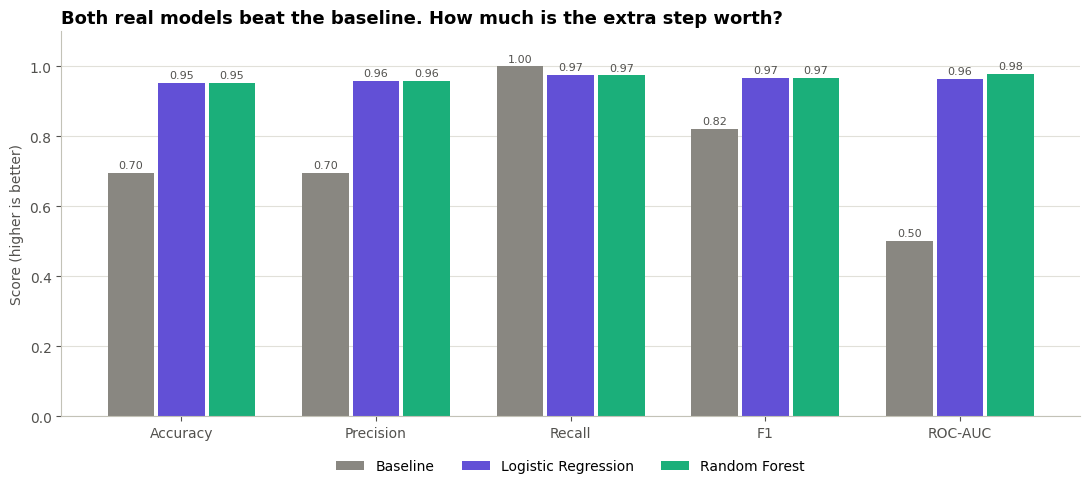

In [21]:
res = pd.DataFrame(results).T
print(res.round(3))

metrics = res.columns
x = np.arange(len(metrics)); w = 0.26
fig, ax = plt.subplots(figsize=(11, 5))
for i, name in enumerate(res.index):
    b = ax.bar(x + (i - 1) * w, res.loc[name], w * 0.92, label=name, color=MODEL_COLORS[name])
    ax.bar_label(b, fmt='%.2f', fontsize=8, padding=2, color='#52514e')
ax.set_xticks(x, metrics)
ax.set_ylim(0, 1.1); ax.set_ylabel("Score (higher is better)")
ax.set_title("Both real models beat the baseline. How much is the extra step worth?")
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

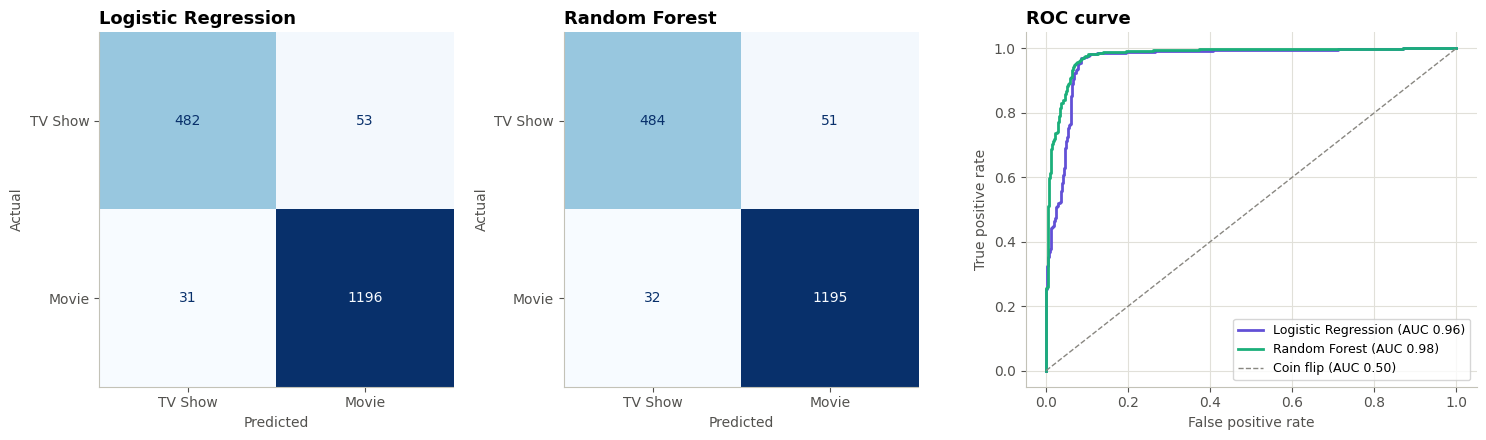

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), gridspec_kw={'width_ratios': [1, 1, 1.25]})

for ax, (name, m) in zip(axes[:2], [('Logistic Regression', log_reg), ('Random Forest', forest)]):
    ConfusionMatrixDisplay.from_predictions(y_test, m.predict(X_test), display_labels=['TV Show', 'Movie'],
                                            cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name); ax.grid(False)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")

ax = axes[2]
for name, m in [('Logistic Regression', log_reg), ('Random Forest', forest)]:
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    ax.plot(fpr, tpr, linewidth=2, color=MODEL_COLORS[name], label=f"{name} (AUC {results[name]['ROC-AUC']:.2f})")
ax.plot([0, 1], [0, 1], '--', color=GRAY, linewidth=1, label='Coin flip (AUC 0.50)')
ax.set_title("ROC curve"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout(); plt.show()

**Reading a confusion matrix:** rows are the truth, columns are the guess. The diagonal (top-left, bottom-right) is correct; the other two boxes are mistakes:
- **Top-right:** TV shows the model called movies (false positives)
- **Bottom-left:** movies the model called TV shows (false negatives)

**Reading a ROC curve:** the closer the curve hugs the **top-left corner**, the better the model separates movies from TV shows. The dashed line is random guessing.

### 3.9 How much should we trust these numbers? Cross-validation

Our test score came from **one** random split. A different split might give a slightly different score. **5-fold cross-validation** splits the training data 5 different ways and tests on each piece, so we get 5 scores and can see how much they wobble.

Baseline             accuracy per fold: [0.696 0.696 0.696 0.696 0.696] → mean 0.696 ± 0.000
Logistic Regression  accuracy per fold: [0.959 0.955 0.941 0.958 0.952] → mean 0.953 ± 0.006
Random Forest        accuracy per fold: [0.96  0.954 0.941 0.959 0.951] → mean 0.953 ± 0.007


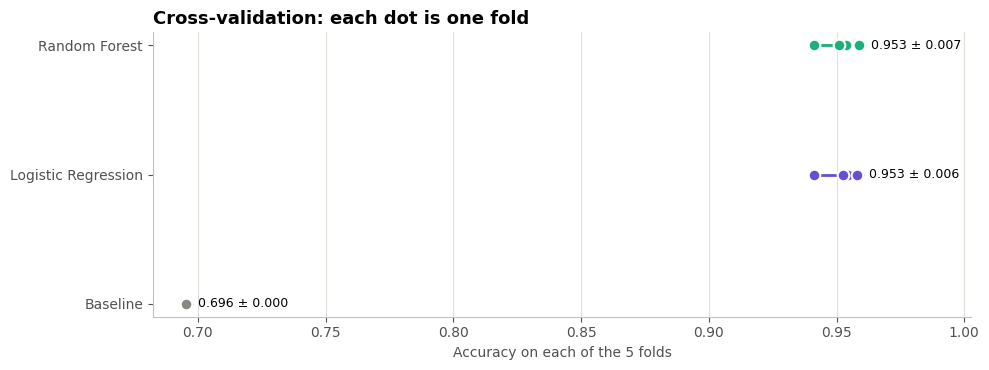

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = {name: cross_val_score(m, X_train, y_train, cv=cv, scoring='accuracy')
             for name, m in [('Baseline', DummyClassifier(strategy='most_frequent')),
                             ('Logistic Regression', log_reg), ('Random Forest', forest)]}

fig, ax = plt.subplots(figsize=(10, 3.8))
for i, (name, s) in enumerate(cv_scores.items()):
    ax.scatter(s, np.full(len(s), i), s=70, color=MODEL_COLORS[name], zorder=3, edgecolor='white', linewidth=1.5)
    ax.plot([s.min(), s.max()], [i, i], color=MODEL_COLORS[name], linewidth=2, zorder=2)
    ax.text(s.max() + 0.004, i, f"{s.mean():.3f} ± {s.std():.3f}", va='center', fontsize=9)
    print(f"{name:<20} accuracy per fold: {np.round(s, 3)} → mean {s.mean():.3f} ± {s.std():.3f}")
ax.set_yticks(range(len(cv_scores)), list(cv_scores.keys()))
ax.set_xlabel("Accuracy on each of the 5 folds")
ax.set_title("Cross-validation: each dot is one fold")
ax.grid(axis='y', visible=False)
ax.set_xlim(right=ax.get_xlim()[1] + 0.03)
plt.tight_layout(); plt.show()

> 🧠 **Think:** If two models' ranges overlap a lot, we can't really claim one is better. The difference could be luck of the split. If the gap is small, the **simpler, more explainable** model (logistic regression) is often the smarter choice.

### 3.10 How confident is the model? And should 0.5 be the cutoff?

The model doesn't just say "Movie"; it gives a **probability**. Let's see how those probabilities look for real movies vs real TV shows.

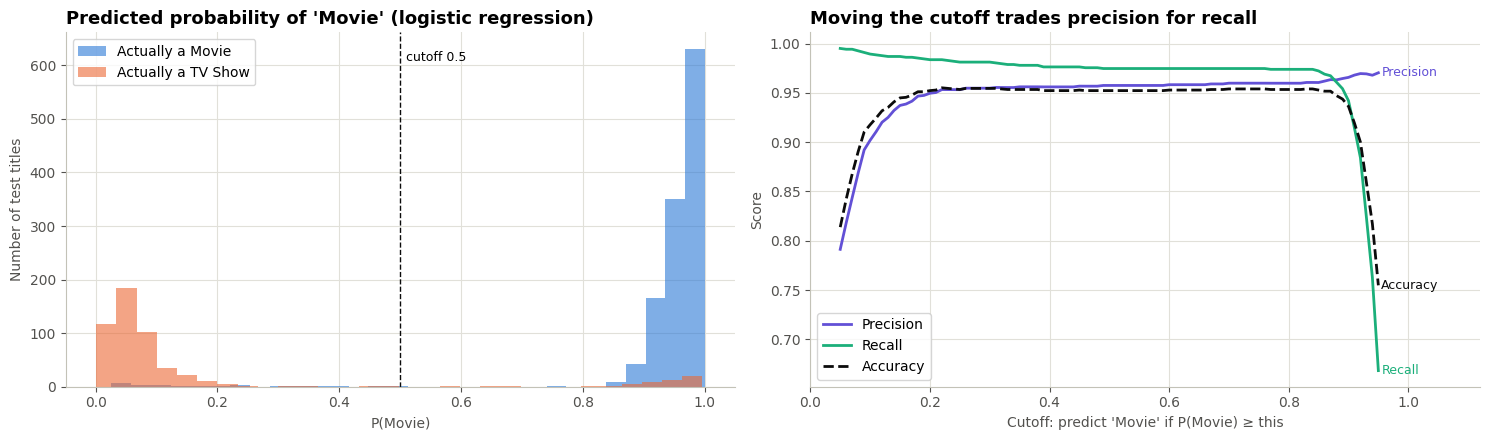

In [24]:
proba_lr = log_reg.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
ax = axes[0]
for t, label in [(1, 'Movie'), (0, 'TV Show')]:
    ax.hist(proba_lr[y_test.values == t], bins=30, alpha=0.6, color=TYPE_COLORS[label], label=f"Actually a {label}")
ax.axvline(0.5, color='#0b0b0b', linestyle='--', linewidth=1)
ax.text(0.51, ax.get_ylim()[1] * 0.92, "cutoff 0.5", fontsize=9)
ax.set_title("Predicted probability of 'Movie' (logistic regression)")
ax.set_xlabel("P(Movie)"); ax.set_ylabel("Number of test titles")
ax.legend(loc='upper left')

ax = axes[1]
thresholds = np.linspace(0.05, 0.95, 91)
lines = {
    'Precision': [precision_score(y_test, proba_lr >= t, zero_division=0) for t in thresholds],
    'Recall':    [recall_score(y_test, proba_lr >= t) for t in thresholds],
    'Accuracy':  [accuracy_score(y_test, proba_lr >= t) for t in thresholds],
}
line_colors = {'Precision': '#6250d6', 'Recall': '#1baf7a', 'Accuracy': '#0b0b0b'}
for name, vals in lines.items():
    ax.plot(thresholds, vals, linewidth=2, color=line_colors[name], label=name,
            linestyle='--' if name == 'Accuracy' else '-')
    ax.text(0.955, vals[-1], name, color=line_colors[name], va='center', fontsize=9)
ax.set_title("Moving the cutoff trades precision for recall")
ax.set_xlabel("Cutoff: predict 'Movie' if P(Movie) ≥ this"); ax.set_ylabel("Score")
ax.set_xlim(0, 1.12); ax.legend(loc='lower left')
plt.tight_layout(); plt.show()

> 🧠 **Think:** Raising the cutoff means the model only says "Movie" when it's very sure: **precision goes up, recall goes down.** Which matters more depends on the real-world cost of each mistake. There's no single "correct" cutoff.
>
> ✏️ **Your turn:** Pick a cutoff, e.g. `0.7`, and compute the confusion matrix with `confusion_matrix(y_test, proba_lr >= 0.7)`. What changed?

### 3.11 Error analysis: where does the model get it wrong?

Looking at mistakes is one of the most valuable habits in data science. Here are the test titles the model was **most confidently wrong** about.

In [25]:
errors = df.loc[X_test.index, ['title', 'type', 'director', 'rating', 'release_year', 'listed_in']].copy()
errors['P(Movie)'] = proba_lr.round(3)
errors['predicted'] = np.where(proba_lr >= 0.5, 'Movie', 'TV Show')
wrong = errors[errors['predicted'] != errors['type']]
wrong = wrong.assign(confidence=(wrong['P(Movie)'] - 0.5).abs()).sort_values('confidence', ascending=False)

print(f"The model got {len(wrong):,} of {len(errors):,} test titles wrong.")
print(f"Wrong TV shows with a director listed: "
      f"{(~is_missing(wrong.loc[wrong['type']=='TV Show','director'])).mean()*100:.0f}%")
wrong.drop(columns='confidence').head(10)

The model got 84 of 1,762 test titles wrong.
Wrong TV shows with a director listed: 96%


,title,type,director,rating,release_year,listed_in,P(Movie),predicted
2813,Ken Burns Presents: College Behind Bars: A Fil...,TV Show,Lynn Novick,TV-MA,2019,Docuseries,0.996,Movie
8172,Th Eena Meena Deeka Chase Comedy Show,TV Show,Dheeraj Berry,TV-Y7,2015,"Kids' TV, TV Comedies",0.988,Movie
4906,Bobby Kennedy for President,TV Show,Dawn Porter,TV-MA,2018,Docuseries,0.988,Movie
1463,The Cat in the Hat Knows a Lot About That!,TV Show,Tony Collingwood,TV-Y,2014,Kids' TV,0.987,Movie
4284,Ellen DeGeneres: Relatable,TV Show,"Joel Gallen, Tig Notaro",TV-MA,2018,"Stand-Up Comedy & Talk Shows, TV Comedies",0.985,Movie
6810,Frozen Planet,TV Show,Alastair Fothergill,TV-PG,2011,"British TV Shows, Docuseries, International TV...",0.984,Movie
2507,Patton Oswalt: I Love Everything,TV Show,Marcus Raboy,TV-MA,2020,"Stand-Up Comedy & Talk Shows, TV Comedies",0.983,Movie
4514,FIGHTWORLD,TV Show,Padraic McKinley,TV-MA,2018,Docuseries,0.977,Movie
2890,Unabomber - In His Own Words,TV Show,Mick Grogan,TV-MA,2018,"Crime TV Shows, Docuseries",0.976,Movie
7375,Maggie & Bianca: Fashion Friends,TV Show,Iginio Straffi,TV-Y7,2017,"Kids' TV, TV Comedies",0.976,Movie


> 🧠 **Think:** Look at the `listed_in` column of the mistakes. Many are **docuseries, stand-up comedy, or kids' content**: titles that "break the usual rules." Many confused TV shows *do* list a director. Can you spot other patterns? This is how you'd decide what feature to add next.

### 3.12 ✏️ Try it yourself: classify a made-up title
Change the values below and see how the prediction changes!

In [26]:
my_title = pd.DataFrame([{
    'title': 'The Great Data Bake Off',
    'director': None,                       # try a name like 'Jane Smith'
    'cast': 'Ana Lee, Sam Park, Chris Diaz',
    'country': 'United Kingdom',
    'date_added': 'March 5, 2021',
    'release_year': 2020,
    'rating': 'TV-PG',                      # try 'PG-13' or 'R'
    'description': 'Amateur bakers compete in themed challenges to win the title of best baker.',
}])

p = log_reg.predict_proba(build_features(my_title)[X_train.columns])[0, 1]
print(f"'{my_title.loc[0, 'title']}' → P(Movie) = {p:.2f} → predicted: {'🎬 Movie' if p >= 0.5 else '📺 TV Show'}")

'The Great Data Bake Off' → P(Movie) = 0.03 → predicted: 📺 TV Show


---
## Part 4: What the Model Can and Cannot Say (Limitations & Ethics)

A model is only responsible if we're honest about its limits.

### ✅ What our results CAN say
- In **this Netflix dataset**, rating, release year and whether a director is listed are strongly **associated** with type.
- Without the leaky `duration` and `genre` columns, a simple model still does clearly better than guessing "Movie" every time.

### ❌ What our results CANNOT say
- **Correlation ≠ causation.** A missing director doesn't *cause* anything. It's how the data was recorded.
- **It may not generalize.** The data is a snapshot of one platform up to about 2021. Other platforms (or Netflix today) may record data differently.
- **The model learns data-entry habits.** If Netflix starts listing directors for TV shows, our model's strongest clue breaks overnight. This is called **data drift**.
- **The test score is an estimate,** with uncertainty (see the cross-validation spread), not a guarantee.

### ⚖️ Does the model work equally well for everyone? A fairness check
A model can have good *overall* accuracy while failing a particular group. Let's check whether it works as well for **US** vs **international** titles.

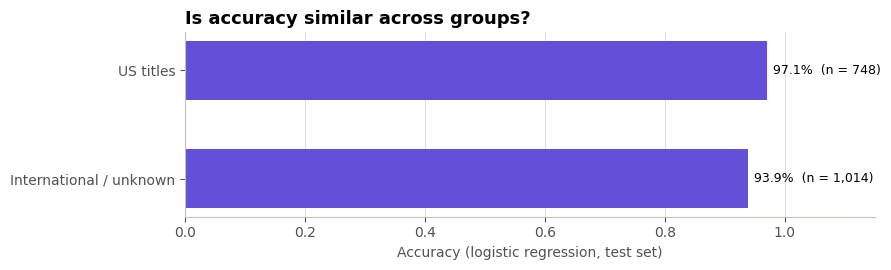

In [27]:
group = np.where(X_test['is_us'] == 1, 'US titles', 'International / unknown')
pred_lr = log_reg.predict(X_test)
by_group = (pd.DataFrame({'group': group, 'correct': pred_lr == y_test.values})
              .groupby('group')['correct'].agg(['mean', 'size']))

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.barh(by_group.index, by_group['mean'], color=MODEL_COLORS['Logistic Regression'], height=0.55)
for i, (acc, n) in enumerate(zip(by_group['mean'], by_group['size'])):
    ax.text(acc + 0.01, i, f"{acc*100:.1f}%  (n = {n:,})", va='center', fontsize=9)
ax.set_xlim(0, 1.15); ax.set_xlabel("Accuracy (logistic regression, test set)")
ax.set_title("Is accuracy similar across groups?")
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

> 🧠 **Think:** If one group's accuracy is noticeably lower, the model's mistakes aren't spread evenly. For a movie/TV label the stakes are low, but the **same check** matters a lot for models that decide loans, hiring, or medical care. **Always check subgroups, not just the overall score.**

### 💭 Other ethical questions to discuss
- **Who is affected by mistakes?** If this model sorted titles for a recommendation system, a TV show mislabeled as a movie could be hidden from viewers looking for series, hurting smaller international creators most.
- **Is the data complete?** Missing values aren't random: international titles more often lack cast/country info. Our model may quietly work worse for them.
- **Should a human check the output?** For low-stakes labels, maybe not. For high-stakes decisions, always.

---
## Part 5: Conclusions

These conclusions are written **from the results above**, so they update automatically if the data or models change.

In [28]:
best = res.drop('Baseline')['Accuracy'].idxmax()
lr_cv, rf_cv = cv_scores['Logistic Regression'], cv_scores['Random Forest']
top3 = coefs.abs().sort_values(ascending=False).index[:3].tolist()

print("📝 KEY FINDINGS\n")
print(f"1. Statistical tests: TV shows are {diff:.1f} years newer on average "
      f"(95% CI {ci_low:.2f} to {ci_high:.2f}, p = {p_value:.1e}, Cohen's d = {cohens_d:.2f}).")
print(f"   Rating and type are related (chi-square p = {p_chi:.1e}, Cramér's V = {cramers_v:.2f}).\n")
print(f"2. Data leakage: 'duration' alone scored {leaky_acc*100:.1f}% because its units give the answer away. We removed it.\n")
print(f"3. Baseline (always 'Movie'): {results['Baseline']['Accuracy']*100:.1f}% accuracy, but it never finds a TV show.\n")
print(f"4. Logistic regression: {results['Logistic Regression']['Accuracy']*100:.1f}% test accuracy "
      f"(cross-validation {lr_cv.mean()*100:.1f}% ± {lr_cv.std()*100:.1f}%), AUC {results['Logistic Regression']['ROC-AUC']:.2f}.")
print(f"   Random forest:       {results['Random Forest']['Accuracy']*100:.1f}% test accuracy "
      f"(cross-validation {rf_cv.mean()*100:.1f}% ± {rf_cv.std()*100:.1f}%), AUC {results['Random Forest']['ROC-AUC']:.2f}.")
print(f"   Best on the test set: {best}.\n")
print(f"5. Strongest logistic regression clues: {', '.join(top3)}.\n")
gap = abs(lr_cv.mean() - rf_cv.mean())
print("6. Recommendation: " + (
    "the two models are within about 1 percentage point, so logistic regression is the better choice: "
    "it's simpler and we can explain every weight." if gap < 0.01 else
    f"{best} is meaningfully better here, but we lose some explainability with a random forest." if best == 'Random Forest' else
    "logistic regression wins on both accuracy and explainability."))

📝 KEY FINDINGS

1. Statistical tests: TV shows are 3.5 years newer on average (95% CI 3.18 to 3.82, p = 3.7e-95, Cohen's d = 0.44).
   Rating and type are related (chi-square p = 7.5e-219, Cramér's V = 0.34).

2. Data leakage: 'duration' alone scored 99.7% because its units give the answer away. We removed it.

3. Baseline (always 'Movie'): 69.6% accuracy, but it never finds a TV show.

4. Logistic regression: 95.2% test accuracy (cross-validation 95.3% ± 0.6%), AUC 0.96.
   Random forest:       95.3% test accuracy (cross-validation 95.3% ± 0.7%), AUC 0.98.
   Best on the test set: Random Forest.

5. Strongest logistic regression clues: director_missing, rating_PG-13, rating_R.

6. Recommendation: the two models are within about 1 percentage point, so logistic regression is the better choice: it's simpler and we can explain every weight.


### 🎓 What you practiced
| Skill | Where you used it |
|---|---|
| Hypothesis testing (t-test, Mann-Whitney, chi-square) | Part 2 |
| Confidence intervals & the bootstrap | Part 2 |
| Effect size (Cohen's d, Cramér's V) | Part 2 |
| Feature engineering & one-hot encoding | 3.1 |
| Spotting **data leakage** | 3.2 |
| Train/test split, baselines, pipelines | 3.3–3.5 |
| Interpreting coefficients & feature importance | 3.6–3.7 |
| Accuracy, precision, recall, F1, ROC-AUC, confusion matrix | 3.8 |
| Cross-validation (uncertainty) | 3.9 |
| Thresholds & error analysis | 3.10–3.11 |
| Limitations, fairness, ethics | Part 4 |

### 🤔 Reflection questions (answer in a markdown cell below)
1. Which of your predictions at the top were right? Which surprised you?
2. Explain **data leakage** to a friend who has never taken a data class, using the `duration` example.
3. Our baseline had high accuracy but was useless. Why? Which metric exposed it?
4. Would you trust this model on Disney+ or Hulu data? Why or why not?
5. Name one feature you could add that might help, and one that would be leakage.

### 🚀 Extension challenges
- **Add text clues:** does the description contain words like *"season"*, *"series"*, or *"documentary"*? (Is "season" leakage? Argue both sides!)
- **Tune the forest:** try `max_depth` of 5, 10, 20, None and plot test accuracy. Where does overfitting begin?
- **Balance the classes:** add `class_weight='balanced'` to `LogisticRegression`. What happens to recall for TV shows?
- **Another test:** use a chi-square test to check whether `director_missing` is related to type.